In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA = ROOT / "data" / "processed"
OUT = ROOT / "outputs" / "metrics"
FIG = ROOT / "outputs" / "figures"

FIG.mkdir(parents=True, exist_ok=True)

X_test = pd.read_csv(DATA / "X_test.csv")
y_test = pd.read_csv(
    DATA / "y_test.csv"
).squeeze("columns")

model = joblib.load(
    ROOT / "models" / "best_model.joblib"
)

results = pd.read_csv(
    OUT / "model_comparison.csv"
)

print("Model and test data loaded successfully!")
print("Test samples:", len(X_test))
display(results)

Model and test data loaded successfully!
Test samples: 61


,Model,CV Accuracy,CV ROC-AUC
0,Logistic Regression,0.846173,0.927830
1,Random Forest,0.858844,0.906656
2,SVM,0.875255,0.917353


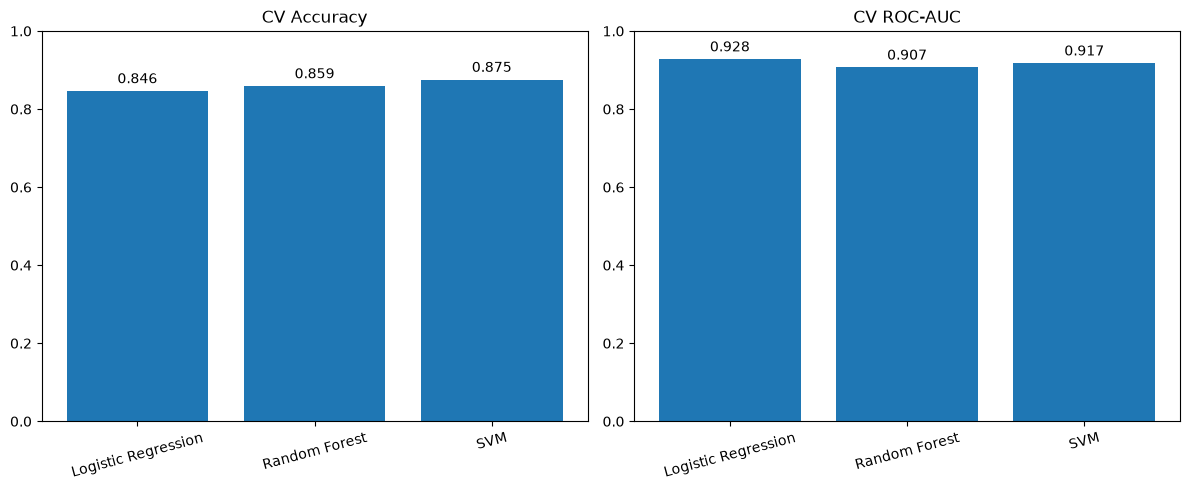

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

metrics = ["CV Accuracy", "CV ROC-AUC"]

for ax, metric in zip(axes, metrics):
    bars = ax.bar(results["Model"], results[metric])

    ax.set_title(metric)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=15)

    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.02,
            f"{height:.3f}",
            ha="center"
        )

plt.tight_layout()
plt.savefig(FIG / "model_comparison.png", dpi=300)
plt.show()

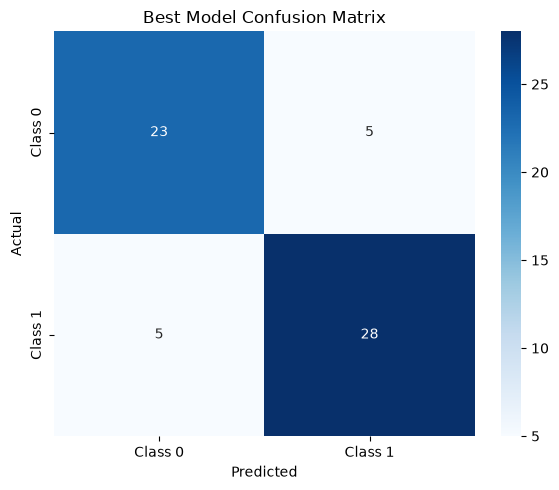

In [3]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Best Model Confusion Matrix")

plt.tight_layout()
plt.savefig(FIG / "confusion_matrix.png", dpi=300)
plt.show()

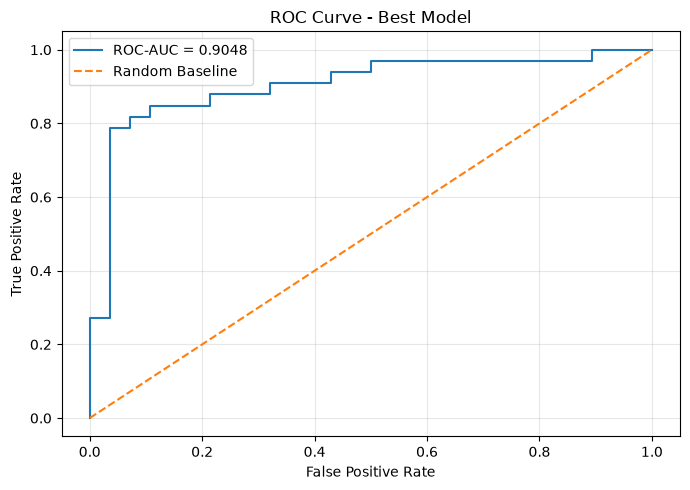

In [4]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"ROC-AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], "--", label="Random Baseline")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Best Model")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIG / "roc_curve.png", dpi=300)
plt.show()

In [ ]:
report = classification_report(
    y_test, y_pred,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).T.to_csv(
    OUT / "classification_report.csv"
)

predictions = X_test.copy()
predictions["Actual"] = y_test.to_numpy()
predictions["Predicted"] = y_pred
predictions["Probability"] = y_prob

predictions.to_csv(
    OUT / "test_predictions.csv",
    index=False
)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred), 4
))

print("ROC-AUC:", round(auc, 4))

print("\nEvaluation completed successfully!")
print("All charts and results saved.")

Accuracy: 0.8361
ROC-AUC: 0.9048

Evaluation completed successfully!
All charts and results saved.


: 